# 01 — The environment

Before training any agent, we check that the environment does exactly what we decided (see the README):

1. the 10 letters and their natural starting points are correctly defined;
2. an agent playing at random behaves as expected (it scribbles);
3. every reward rule gives the expected value;
4. the full model, needed by dynamic programming, can be built.

In [1]:
import sys
sys.path.insert(0, "..")  # so that Python finds the src/ folder

import numpy as np
import matplotlib.pyplot as plt

from src.letters import make_letter, TRAINING_LETTERS
from src.environment import LetterWritingEnv, Rewards, make_action, action_name, STOP, N_ACTIONS
from src.visualization import plot_letters, draw_episode

## 1. The letters

Each letter is a set of unit segments. The number of states is
25 positions × 2 (pen down or not) × 2^(number of segments).

letter   segments    states
I               8    12,800
L               7     6,400
T               8    12,800
E              12   204,800
F               9    25,600
H              12   204,800
N              12   204,800
Z              12   204,800
V               8    12,800
X               8    12,800


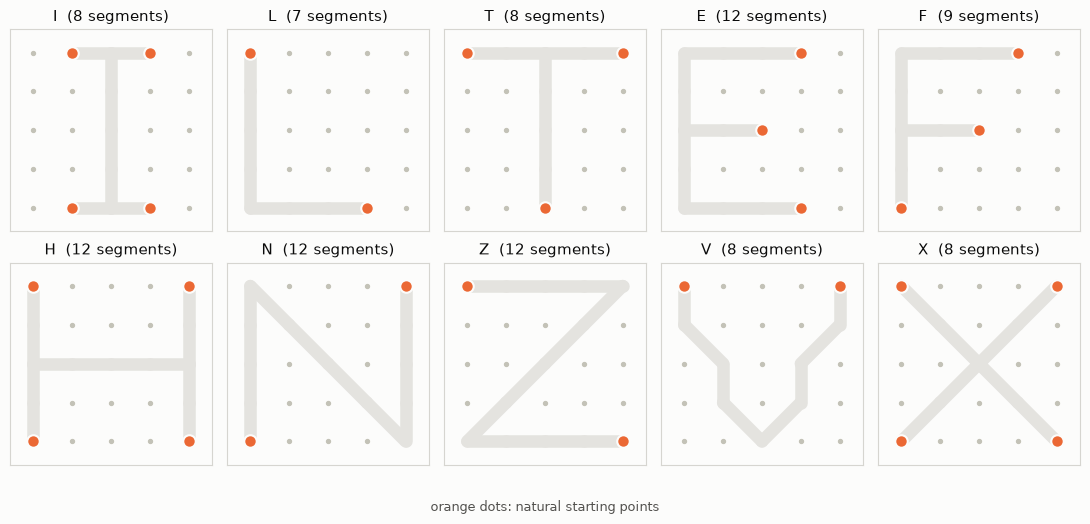

In [2]:
letters = [make_letter(name) for name in TRAINING_LETTERS]

print(f"{'letter':<8}{'segments':>9}{'states':>10}")
for letter in letters:
    env = LetterWritingEnv(letter)
    print(f"{letter.name:<8}{letter.n_segments:>9}{env.n_states:>10,}")

plot_letters(letters, path="../results/01_letters.png")
plt.show()

## 2. A random agent

The agent picks one of the 17 actions uniformly at random at each step, until it presses STOP
or reaches the limit of 50 steps. This is what a learning agent does at the very beginning,
when it knows nothing yet.

steps: 15   total reward: -10.60
segments drawn: 3 / 12
ended by: STOP


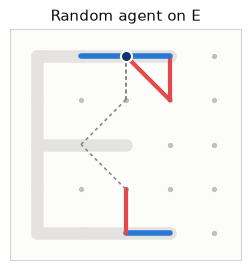

In [3]:
env = LetterWritingEnv("E", seed=0)
rng = np.random.default_rng(0)

state = env.reset()
total_reward, terminated, truncated = 0.0, False, False
while not (terminated or truncated):
    action = rng.integers(N_ACTIONS)
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

print(f"steps: {env.steps}   total reward: {total_reward:.2f}")
print(f"segments drawn: {env.drawn_segments()} / {env.k}")
print("ended by:", "STOP" if terminated else "step limit")

fig, ax = plt.subplots(figsize=(3, 3))
draw_episode(ax, env.letter, env.history, title="Random agent on E")
plt.show()

**What to notice:** blue = segments of the letter drawn, red = segments drawn outside the letter,
dashed grey = moves with the pen up. With 17 possible actions, STOP is chosen on average every
17 steps, so random episodes are short and the letter is almost never completed.
The total reward is strongly negative: this is the starting point that learning must improve.

## 3. Checking the rules

We play short sequences of actions chosen by hand and compare the total reward with the value
computed by hand from the reward table. If a rule were badly coded, an `assert` would fail.

In [4]:
def play(letter, start, actions):
    """Play a fixed sequence of actions from a given start. Returns (total reward, env)."""
    env = LetterWritingEnv(letter)
    env.reset(start=start)
    total = 0.0
    for a in actions:
        _, reward, terminated, truncated, _ = env.step(a)
        total += reward
    return total, env

down_pd = make_action("down", pen_down=True)
right_pd = make_action("right", pen_down=True)
up_pd = make_action("up", pen_down=True)
down_pu = make_action("down", pen_down=False)
up_pu = make_action("up", pen_down=False)

# (a) Draw the whole L in one stroke, then STOP.
#     1 new stroke (-0.3) + 7 moves (-0.05 each) + 7 new segments (+1 each) + STOP complete (+2)
total, env = play("L", (0, 0), [down_pd] * 4 + [right_pd] * 3 + [STOP])
assert np.isclose(total, -0.3 + 7 * -0.05 + 7 * 1 + 2), total
print(f"(a) whole L then STOP:        {total:+.2f}")

# (b) One segment outside the letter: move + new stroke + off-letter
total, env = play("L", (0, 0), [right_pd])
assert np.isclose(total, -0.05 - 0.3 - 1), total
print(f"(b) segment outside letter:   {total:+.2f}")

# (c) Going back over a segment: the second time gives no +1 (and no new-stroke penalty)
total, env = play("L", (0, 0), [down_pd, up_pd])
assert np.isclose(total, (-0.05 - 0.3 + 1) + (-0.05)), total
print(f"(c) draw, then go back over:  {total:+.2f}")

# (d) Lifting the pen: two strokes = two new-stroke penalties
total, env = play("L", (0, 0), [down_pd, down_pu, down_pd])
assert np.isclose(total, (-0.05 - 0.3 + 1) + (-0.05) + (-0.05 - 0.3 + 1)), total
print(f"(d) two separate strokes:     {total:+.2f}")

# (e) Moving off the grid: penalty, and the pen does not move
total, env = play("L", (0, 0), [up_pu])
assert np.isclose(total, -0.2) and env.decode(env.state)[:2] == (0, 0), total
print(f"(e) move off the grid:        {total:+.2f}")

# (f) STOP immediately: -1 per missing segment (7 segments in L)
total, env = play("L", (0, 0), [STOP])
assert np.isclose(total, -7), total
print(f"(f) STOP immediately:         {total:+.2f}")

# (g) Step limit: after 50 steps the episode is truncated, but not terminated
env = LetterWritingEnv("L")
env.reset(start=(0, 0))
for _ in range(50):
    _, _, terminated, truncated, _ = env.step(up_pu)
assert truncated and not terminated
print("(g) step limit: truncated after 50 steps, not terminated")

print("\nAll checks passed.")

(a) whole L then STOP:        +8.35
(b) segment outside letter:   -1.35
(c) draw, then go back over:  +0.60
(d) two separate strokes:     +1.25
(e) move off the grid:        -0.20
(f) STOP immediately:         -7.00
(g) step limit: truncated after 50 steps, not terminated

All checks passed.


**Terminated vs truncated:** pressing STOP is a real end of the MDP (*terminated*): nothing
comes after. Reaching 50 steps only cuts the episode (*truncated*): the state itself is not
terminal. The difference matters for Q-learning: after a terminated step the target is just
the reward, after a truncated step we still add the estimated value of the next state.

## 4. The full model (for dynamic programming)

Dynamic programming needs to know, for every state *s* and action *a*, the next state and the
reward: this is $p(s', r \mid s, a)$ from the course. Since our environment is deterministic,
each pair $(s, a)$ leads to a single $(s', r)$. `build_model()` computes this table by calling
the same rules as `step()`.

In [5]:
import time

env = LetterWritingEnv("E")
t0 = time.perf_counter()
next_state, reward, terminated = env.build_model()
print(f"model of E: {env.n_states:,} states x {N_ACTIONS} actions, built in {time.perf_counter() - t0:.1f} s")

# One row of the model: what happens from a starting point of E
s0 = env.start_states()[0]
print(f"\nfrom state {env.decode(s0)} = (row, col, pen down, drawn mask):")
for a in range(N_ACTIONS):
    print(f"  {action_name(a):<24} -> next state {env.decode(next_state[s0, a])}, "
          f"reward {reward[s0, a]:+.2f}{', terminal' if terminated[s0, a] else ''}")

model of E: 204,800 states x 17 actions, built in 5.5 s

from state (0, 3, 0, 0) = (row, col, pen down, drawn mask):
  up (pen up)              -> next state (0, 3, 0, 0), reward -0.20
  down (pen up)            -> next state (1, 3, 0, 0), reward -0.05
  left (pen up)            -> next state (0, 2, 0, 0), reward -0.05
  right (pen up)           -> next state (0, 4, 0, 0), reward -0.05
  up-left (pen up)         -> next state (0, 3, 0, 0), reward -0.20
  up-right (pen up)        -> next state (0, 3, 0, 0), reward -0.20
  down-left (pen up)       -> next state (1, 2, 0, 0), reward -0.05
  down-right (pen up)      -> next state (1, 4, 0, 0), reward -0.05
  up (pen down)            -> next state (0, 3, 0, 0), reward -0.20
  down (pen down)          -> next state (1, 3, 1, 0), reward -1.35
  left (pen down)          -> next state (0, 2, 1, 1), reward +0.65
  right (pen down)         -> next state (0, 4, 1, 0), reward -1.35
  up-left (pen down)       -> next state (0, 3, 0, 0), reward -0.20

## Summary

- The 10 letters are defined by their segments; the largest ones (E, H, N, Z) have 12 segments, i.e. 204,800 states.
- A random agent scribbles and gets a strongly negative reward.
- Every reward rule gives the value computed by hand.
- The full model is available for dynamic programming (next step: value iteration).